# ECE 1395 Final Project: Predicting Music Genres
Approach 1: SVM with Audio Features

In [1]:
# set random seed, to be used for all approaches
seed = 4

### Step 1: Load and Prepare Data

In [2]:
import pandas as pd
import random
import numpy as np
from sklearn.model_selection import train_test_split

# load data file with 3-second features (corrupted audio files left out of the csv file) and print shape
musicData = pd.read_csv('./music_data/features_3_sec.csv')
print("features_3_sec.csv shape: ", musicData.shape)

# split training and test data randomly based on song to eliminate data leakage (all 3-second clips from that song will either be in training or test set)
parts = musicData["filename"].str.split(".", expand=True)
musicData["genre"] = parts[0]
musicData["song"] = parts[0] + "." + parts[1]   # e.g. "blues.00000"
musicData["segment"] = parts[2].astype(int)

# split songs into 80% training and 20% testing data
# using stratify argument to ensure that 80% of each genre is in training and 20% of each genre is in testing
songs = musicData[["song", "genre"]].drop_duplicates()
train_songs, test_songs = train_test_split(
    songs,
    test_size=0.2,
    stratify=songs["genre"],
    random_state=seed,
)

# keep all segments of the same song in either training or test set
train_data = musicData[musicData["song"].isin(train_songs["song"])]
test_data  = musicData[musicData["song"].isin(test_songs["song"])]

# set X_train, y_train, X_test, and y_test
drop_cols = ["filename", "length", "label", "genre", "song", "segment"]
X_train = train_data.drop(columns=drop_cols)
y_train = train_data["genre"]
X_test  = test_data.drop(columns=drop_cols)
y_test  = test_data["genre"]

# double check shape of training and test sets
print("\nX_train shape: ", X_train.shape)
print("y_train shape: ", y_train.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)

features_3_sec.csv shape:  (9990, 60)

X_train shape:  (7991, 57)
y_train shape:  (7991,)
X_test shape:  (1999, 57)
y_test shape:  (1999,)


### Step 2: Train SVM Classifiers Without PCA

In [6]:
import time
import numpy as np
from sklearn.svm import SVC
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
import pandas as pd

# train 6 SVM classifiers using same procedure from HW5
# Multi-class strategy: OvO and OvA
# Kernel: linear, 3rd-order polynomial, Gaussian RBF
C = 0.5 * (1+ (seed%4))

# Scale features (fit on train only)
scaler = StandardScaler()
Xtrain = scaler.fit_transform(X_train)
Xtest = scaler.transform(X_test)

kernels = ["linear", "poly", "rbf"]
codings = ["onevsone", "onevsall"]

train_time = np.zeros((3, 2))
test_acc = np.zeros((3, 2))

for k, kernel in enumerate(kernels):
    for c, coding in enumerate(codings):
        if kernel == "poly":
            base = SVC(kernel="poly", degree=3, C=C)
        else:
            base = SVC(kernel=kernel, C=C)

        if coding == "onevsone":
            mdl = OneVsOneClassifier(base)
        else:
            mdl = OneVsRestClassifier(base)

        start = time.time()
        mdl.fit(Xtrain, y_train)
        train_time[k, c] = time.time() - start

        pred = mdl.predict(Xtest)
        test_acc[k, c] = np.mean(pred == y_test) * 100

kernel_labels = ["Linear", "Poly (deg 3)", "RBF"]
coding_labels = ["One-vs-One", "One-vs-All"]

acc_df = pd.DataFrame(test_acc, index=kernel_labels, columns=coding_labels)
time_df = pd.DataFrame(train_time, index=kernel_labels, columns=coding_labels)

print("Test Accuracies (%)")
print(acc_df.round(2))

print("\nTraining Times (Seconds)")
print(time_df.round(4))

Test Accuracies (%)
              One-vs-One  One-vs-All
Linear             63.03       61.88
Poly (deg 3)       57.78       64.48
RBF                63.93       65.63

Training Times (Seconds)
              One-vs-One  One-vs-All
Linear            3.2901     25.0205
Poly (deg 3)      4.9833     17.2662
RBF               4.6342     15.1968


## Step 3: Generate Confusion Matrix for SVM Model with Best Accuracy

Training time: 15.4875 s
Test accuracy: 65.63%
Confusion Matrix:
[[134   3  17  12   3   6   8   0  13   4]
 [  0 177   3   0   0  13   0   0   0   6]
 [  5   7 135  16   2   8   0   2  12  13]
 [  6   1   6 115  22  17   1   7   9  16]
 [  6   4  12  10 123   0  10   7  19   9]
 [  6  42   5   3   1 142   0   1   0   0]
 [  0   1   4   8  12   1 169   0   1   4]
 [  0   6   7  11  12   2   0 161   0   1]
 [ 18   1  31   9  23   2   7  10  93   6]
 [  7   7  21  28   1  18  40  12   3  63]]


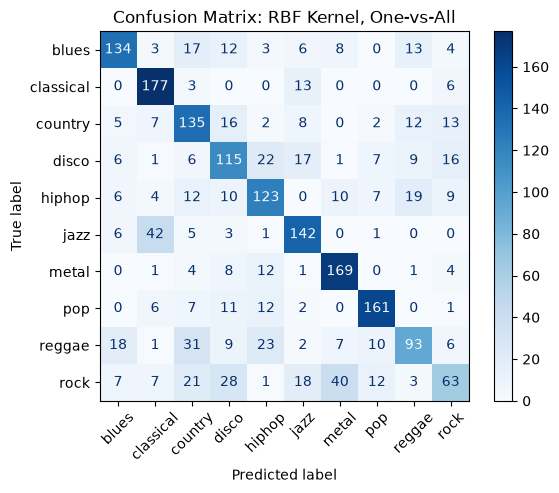

In [5]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Re-run one-vs-all with RBF kernel
mdl = OneVsRestClassifier(SVC(kernel="rbf", C=C))

start = time.time()
mdl.fit(Xtrain, y_train)
rbf_ova_time = time.time() - start

pred = mdl.predict(Xtest)
rbf_ova_acc = np.mean(pred == y_test) * 100

print(f"Training time: {rbf_ova_time:.4f} s")
print(f"Test accuracy: {rbf_ova_acc:.2f}%")

# Confusion matrix
cm = confusion_matrix(y_test, pred)
print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=mdl.classes_)
disp.plot(cmap="Blues", values_format="d", xticks_rotation=45)
plt.title("Confusion Matrix: RBF Kernel, One-vs-All")
plt.show()

### Step 4: Testing SVM Classifiers with PCA

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# standardize data
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0, ddof=1)
sigma[sigma == 0] = 1.0

Xtrain_s = (X_train - mu) / sigma
Xtest_s = (X_test - mu) / sigma

# covariance matrix of the training data
n = Xtrain_s.shape[0]
cov = (Xtrain_s.T @ Xtrain_s) / (n - 1)

# eigendecomposition
eigvals, eigvecs = np.linalg.eigh(cov)

# sort by eigenvalue, largest first
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

# explained variance and choosing k
var_ratio = eigvals / eigvals.sum()
cum_var = np.cumsum(var_ratio)
k = np.argmax(cum_var >= 0.95) + 1
print(f"Components for 95% variance: {k}")

# project onto the top k components
W = eigvecs[:, :k]
Xtrain_p = Xtrain_s @ W
Xtest_p = Xtest_s @ W

print(Xtrain_p.shape, Xtest_p.shape)

# plot
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o", markersize=3)
plt.axhline(0.95, color="r", linestyle="--")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.grid(True)
plt.show()

In [ ]:
import time
import numpy as np
from sklearn.svm import SVC
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.preprocessing import StandardScaler

# train 6 SVM classifiers using same procedure from HW5
# Multi-class strategy: OvO and OvA
# Kernel: linear, 3rd-order polynomial, Gaussian RBF
C = 0.5 * (1+ (seed%4))

# Scale features
scaler = StandardScaler()
Xtrain_p = scaler.fit_transform(Xtrain_p)
Xtest_p = scaler.transform(Xtest_p)

kernels = ["linear", "poly", "rbf"]
codings = ["onevsone", "onevsall"]

train_time = np.zeros((3, 2))
test_acc = np.zeros((3, 2))

for k, kernel in enumerate(kernels):
    for c, coding in enumerate(codings):
        if kernel == "poly":
            base = SVC(kernel="poly", degree=3, C=C)
        else:
            base = SVC(kernel=kernel, C=C)

        if coding == "onevsone":
            mdl = OneVsOneClassifier(base)
        else:
            mdl = OneVsRestClassifier(base)

        start = time.time()
        mdl.fit(Xtrain_p, y_train)
        train_time[k, c] = time.time() - start

        pred = mdl.predict(Xtest_p)
        test_acc[k, c] = np.mean(pred == y_test) * 100

print("Training Times (Seconds)")
print(train_time)
print("Test Accuracies (%)")
print(test_acc)